# Module 3 — Task 3: Unsupervised detection with Isolation Forest

**Business problem (brief, verbatim):**
> NovaFin processes thousands of transactions every day. Management wants to identify suspicious transactions while minimizing unnecessary investigation.

**Task 3 (brief, verbatim):**
> **Task 3 — Unsupervised detection.** Use: Isolation Forest. The objective is to identify transactions that appear unusual even without relying directly on the fraud label. Compare: Supervised detection vs anomaly detection.

**Unsupervised** = the model learns without being told which transactions were fraud. **Anomaly detection** = finding transactions that are unlike the rest.

**Why a bank would want it:** fraud labels arrive late and miss new schemes. A method that needs no labels could catch fraud the label-trained model has never seen.

**Where this task sits:** data (Task 1) → supervised fraud model (Task 2) → **anomaly detection (this task)** → cost-based threshold (Task 4).

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load, the same time split as Task 2, and Task 2's scores |
| 2 | How Isolation Forest works |
| 3 | What it sees: the input tests (decision M3-15) |
| 4 | Fit it on training transactions only, score all (decision M3-17) |
| 5 | What "unusual" looks like |
| 6 | The comparison on 6,000 test transactions: amount alone vs supervised vs Isolation Forest |
| 7 | The finance case: frauds and ₹ caught at each investigation budget |
| 8 | Overlap: do the two methods find the same frauds? |
| 9 | Combining the two |
| 10 | The unusual transactions, each with its reason (the brief's deliverable) |
| 11 | What the results say |
| 12 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M3-15 inputs and comparison · M3-16 output files · M3-17 settings, the unusual list and its reasons.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Takes about 2 minutes. Reads `outputs/task2/FINAL_M3_T2_fraud_scores.csv`, so Task 2 must have run once.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_03_fraud_detection"
TASK2_DIR = MODULE_DIR / "outputs" / "task2"          # Task 2's scores
OUT_DIR = MODULE_DIR / "outputs" / "task3"            # unusual list, scores, comparison, charts
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))

warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"                # avoids a harmless Windows CPU-count warning

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score
import shap                           # explaining why each transaction is unusual

# ---- Module 3 helpers --------------------------------------------------------------------
from m03_data import load_transactions, add_features, make_inputs, INPUT_SETS
from m03_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, FRAUD, NORMAL
apply_style()
plt.close("all")

SEED = 42                             # project decision P-06
LAKH, CRORE = 1e5, 1e7
N_TREES, SAMPLE = 500, 256            # decision M3-17
BUDGETS = [0.01, 0.05, 0.10]          # reading points on the catch curves (not pass lines)
MAIN_INPUTS = ["Amount", "Amount_Ratio", "Historical_Avg_Transaction", "Account_Age_Months",
               "Transaction_Frequency", "Hour"]                       # decision M3-15 (a): chosen without fraud information
SIDE_INPUTS = ["Amount", "Amount_Ratio"]                              # decision M3-15 (b): chosen using Task 1's findings
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 120)


def save_table(table: pd.DataFrame, name: str) -> None:
    """Save a table to outputs/task3/<name>.csv (only deliverables and hand-offs, decision M3-16)."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Reads from:   ", TASK2_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Reads from:    module_03_fraud_detection/outputs/task2
Outputs go to: module_03_fraud_detection/outputs/task3


## 1. Load, the same time split as Task 2, and Task 2's scores

The same split as Task 2: Isolation Forest **learns from the first 24,000 transactions** (Jan 2025 – Apr 2026) and is judged on the **last 6,000** (May – Aug 2026). The comparison with Task 2 is then fair: both see the same "future".

From Task 2 (`FINAL_M3_T2_fraud_scores.csv`): each transaction's P(fraud) from the supervised model, and the amount-alone benchmark score.

In [2]:
tx = add_features(load_transactions())
cut = int(0.8 * len(tx))
tx["Set"] = np.where(np.arange(len(tx)) < cut, "train", "test")
s2 = pd.read_csv(TASK2_DIR / "FINAL_M3_T2_fraud_scores.csv")[["Transaction_ID", "P_fraud", "P_benchmark"]]
tx = tx.merge(s2, on="Transaction_ID", how="left", validate="one_to_one")
assert tx.P_fraud.notna().all(), "Task 2 scores missing: run Task 2 first"

train, test = tx[tx.Set == "train"].reset_index(drop=True), tx[tx.Set == "test"].reset_index(drop=True)
y_train, y_test = train.Fraud_Flag.to_numpy(), test.Fraud_Flag.to_numpy()
amt_train, amt_test = train.Amount.to_numpy(), test.Amount.to_numpy()
FRAUD_SHARE = y_train.mean()                          # 2.25%: the share flagged as unusual (decision M3-17)
print(f"Training {len(train):,} ({y_train.sum()} frauds), test {len(test):,} ({y_test.sum()} frauds)")
print(f"Share to flag as unusual = training-period fraud rate = {y_train.sum()} ÷ {len(train):,} = {FRAUD_SHARE:.2%}")

Training 24,000 (540 frauds), test 6,000 (144 frauds)
Share to flag as unusual = training-period fraud rate = 540 ÷ 24,000 = 2.25%


## 2. How Isolation Forest works

**The idea:** unusual points are *easy to isolate*. Pick an input at random, cut its range at a random value, and keep cutting the side the transaction falls in. A normal transaction, surrounded by similar ones, needs many cuts before it stands alone. An unusual one is cut off in a few.

```text
Each tree: take a random sample of 256 transactions; cut at random until every transaction stands alone
Path length h(x) = number of cuts needed to isolate transaction x in one tree
Anomaly score s(x) = 2 ^ ( − average h(x) over all trees ÷ c(256) )
c(n) = 2 × H(n − 1) − 2 × (n − 1) ÷ n,   H(k) ≈ ln(k) + 0.5772      (the average path length expected for n points)
s close to 1 → isolated quickly → unusual;   s around 0.5 or below → normal
```

- **500 trees** (M3-17): the unusual list is steadier between random seeds (93% of the list stays the same, against 84% with 100 trees).
- **256 transactions per tree:** small samples isolate unusual points better. With all 24,000, normal transactions crowd around the unusual ones (tested: PR-AUC 0.089 at 256 vs 0.068 with all).
- **It never sees Fraud_Flag.** The label is used only afterwards, to judge it.

## 3. What Isolation Forest sees: the input tests (decision M3-15)

**Main model (a):** every numeric description of the transaction, chosen **without** fraud information: amount, amount ratio, usual amount, account age, transaction frequency, hour. On **raw ₹**: the bank's money is at risk in unusually *large* outflows. On a log scale, unusually *small* transactions look just as odd, but they risk almost nothing.

**Side check (b):** amount and amount ratio only, chosen using Task 1's findings (which did use the fraud label). It answers: *is Isolation Forest behind because "unusual" isn't "fraud", or because of what it was given?*

**The tests that led there** (training transactions, 3 seeds; the label judges, never fits). They are re-run here so the evidence sits with the decision. Category columns are encoded in ways that need no label: how common each value is, how rare the type × merchant × city combination is, and whether this city or type is new for the customer.

In [3]:
def iforest(seed=SEED, n_trees=200):
    """Isolation Forest with the agreed sample size; fewer trees here to keep the input tests quick."""
    return IsolationForest(n_estimators=n_trees, max_samples=SAMPLE, random_state=seed, n_jobs=4)


def anomaly(model, X):
    """Anomaly score s(x): higher = more unusual (score_samples returns −s)."""
    return -model.score_samples(X)


cats = ["Transaction_Type", "Merchant_Category", "Location", "Weekday"]
freq = pd.DataFrame({f"{c} frequency": train[c].map(train[c].value_counts(normalize=True)).astype(float) for c in cats})
combo = train.Transaction_Type.astype(str) + "|" + train.Merchant_Category.astype(str) + "|" + train.Location.astype(str)
combo_rarity = combo.map(combo.value_counts(normalize=True)).rename("combination frequency")
new_city = train.groupby(["Customer_ID", "Location"], observed=True).cumcount().eq(0).astype(float).rename("new city")
new_type = train.groupby(["Customer_ID", "Transaction_Type"], observed=True).cumcount().eq(0).astype(float).rename("new type")
raw = train[MAIN_INPUTS].astype(float)
logged = raw.assign(Amount=np.log(raw.Amount), Amount_Ratio=np.log(raw.Amount_Ratio),
                    Historical_Avg_Transaction=np.log(raw.Historical_Avg_Transaction))
options = {
    "(a) six numeric descriptors, raw ₹ [chosen]": raw,
    "(b) amount + amount ratio, raw ₹ [side check]": train[SIDE_INPUTS].astype(float),
    "Same six, money logged": logged,
    "All 28 Task 2 inputs (incl. 0/1 category columns)": make_inputs(train, INPUT_SETS["All columns"]),
    "(a) + how common each category value is": pd.concat([raw, freq], axis=1),
    "(a) + combination rarity": pd.concat([raw, combo_rarity], axis=1),
    "(a) + device / city change": pd.concat([raw, train[["Device_Change", "Location_Change"]].astype(float)], axis=1),
    "(a) + new city / new type for the customer": pd.concat([raw, new_city, new_type], axis=1),
    "Category signals only": pd.concat([freq, combo_rarity, new_city, new_type,
                                        train[["Device_Change", "Location_Change"]].astype(float)], axis=1)}
rows = []
for name, X in options.items():
    prs = []
    for seed in [SEED, SEED + 1, SEED + 2]:
        s = anomaly(iforest(seed).fit(X.values), X.values)
        prs.append(average_precision_score(y_train, s))
    top = np.argsort(-s)[: int(0.05 * len(s))]
    rows.append({"What Isolation Forest sees": name, "PR-AUC (3 seeds) low": min(prs), "high": max(prs),
                 "Top 5%: frauds caught": y_train[top].sum() / y_train.sum(),
                 "Top 5%: fraud ₹ caught": (amt_train[top] * y_train[top]).sum() / (amt_train * y_train).sum(),
                 "Top 5%: share below the median amount": (amt_train[top] < np.median(amt_train)).mean()})
input_tests = pd.DataFrame(rows)
print(f"Guessing scores PR-AUC = fraud rate = {FRAUD_SHARE:.3f}")
input_tests.style.format({"PR-AUC (3 seeds) low": "{:.3f}", "high": "{:.3f}", "Top 5%: frauds caught": "{:.1%}",
                          "Top 5%: fraud ₹ caught": "{:.1%}", "Top 5%: share below the median amount": "{:.0%}"}).hide(axis="index")

Guessing scores PR-AUC = fraud rate = 0.022


What Isolation Forest sees,PR-AUC (3 seeds) low,high,Top 5%: frauds caught,Top 5%: fraud ₹ caught,Top 5%: share below the median amount
"(a) six numeric descriptors, raw ₹ [chosen]",0.087,0.092,26.1%,50.8%,8%
"(b) amount + amount ratio, raw ₹ [side check]",0.109,0.111,31.3%,59.3%,0%
"Same six, money logged",0.043,0.054,13.1%,27.0%,55%
All 28 Task 2 inputs (incl. 0/1 category columns),0.029,0.030,7.0%,11.8%,52%
(a) + how common each category value is,0.075,0.082,27.0%,52.0%,8%
(a) + combination rarity,0.089,0.091,26.5%,52.4%,10%
(a) + device / city change,0.059,0.070,21.5%,42.4%,17%
(a) + new city / new type for the customer,0.085,0.089,25.7%,49.6%,8%
Category signals only,0.023,0.024,6.3%,6.2%,51%


In [4]:
# Why categories can't mark anything here: every value is common, and fraud is no higher where they look unusual.
print("Share of training transactions per value (smallest – largest):")
for c in cats:
    s = train[c].value_counts(normalize=True)
    print(f"  {c:<18} {s.min():.1%} – {s.max():.1%}")
print("Fraud rate by how rare the type × merchant × city combination is (rarest fifth first):",
      [f"{v:.1%}" for v in train.groupby(pd.qcut(combo_rarity, 5, duplicates='drop'), observed=True).Fraud_Flag.mean()])
print("Fraud rate, city new for the customer vs not:",
      {("new" if k else "seen before"): f"{v:.1%}" for k, v in train.groupby(new_city).Fraud_Flag.mean().items()})

Share of training transactions per value (smallest – largest):
  Transaction_Type   20.0% – 55.0%
  Merchant_Category  13.8% – 14.6%
  Location           14.1% – 14.6%
  Weekday            14.2% – 14.4%


Fraud rate by how rare the type × merchant × city combination is (rarest fifth first): ['2.7%', '2.2%', '2.3%', '1.7%', '2.2%']
Fraud rate, city new for the customer vs not: {'seen before': '2.3%', 'new': '2.2%'}


## 4. Fit on training transactions only, score all 30,000 (decision M3-17)

- 500 trees of 256 transactions; fitted on the 24,000 training transactions; scores every transaction.
- **The unusual list:** the 2.25% of transactions with the highest scores. 2.25% is the training-period fraud rate: as many flags as there are frauds, using only a figure a bank knows from past cases. The cut-off score is set on the training transactions and applied unchanged to the test ones.
- **Stability check:** the same model with five different seeds. How much of the unusual list stays the same?

In [5]:
X_main_train, X_main_all = train[MAIN_INPUTS].to_numpy(float), tx[MAIN_INPUTS].to_numpy(float)
X_side_train, X_side_all = train[SIDE_INPUTS].to_numpy(float), tx[SIDE_INPUTS].to_numpy(float)

iso = IsolationForest(n_estimators=N_TREES, max_samples=SAMPLE, contamination=FRAUD_SHARE, random_state=SEED, n_jobs=4)
iso.fit(X_main_train)                                       # never sees Fraud_Flag
iso_side = IsolationForest(n_estimators=N_TREES, max_samples=SAMPLE, random_state=SEED, n_jobs=4).fit(X_side_train)

tx["Anomaly_Score"] = anomaly(iso, X_main_all)
tx["Anomaly_Score_Side"] = anomaly(iso_side, X_side_all)
CUTOFF = np.quantile(tx.loc[tx.Set == "train", "Anomaly_Score"], 1 - FRAUD_SHARE)   # set on training only
tx["Unusual"] = tx.Anomaly_Score >= CUTOFF
train, test = tx[tx.Set == "train"].reset_index(drop=True), tx[tx.Set == "test"].reset_index(drop=True)
print(f"Cut-off anomaly score (from training): {CUTOFF:.4f}")
print(f"Flagged as unusual: training {train.Unusual.sum():,} ({train.Unusual.mean():.2%}), "
      f"test {test.Unusual.sum():,} ({test.Unusual.mean():.2%})")

# Stability: same model, five seeds. Share of the training unusual list shared by two runs.
k = int(round(FRAUD_SHARE * len(train)))
lists = [set(np.argsort(-anomaly(IsolationForest(n_estimators=N_TREES, max_samples=SAMPLE, random_state=s, n_jobs=4)
                                 .fit(X_main_train), X_main_train))[:k]) for s in range(SEED, SEED + 5)]
shared = [len(lists[i] & lists[j]) / k for i in range(5) for j in range(i + 1, 5)]
STABILITY = (np.mean(shared), np.min(shared))
print(f"Two seeds share {STABILITY[0]:.0%} of the unusual list on average (lowest {STABILITY[1]:.0%})")

Cut-off anomaly score (from training): 0.5975
Flagged as unusual: training 540 (2.25%), test 140 (2.33%)


Two seeds share 93% of the unusual list on average (lowest 91%)


## 5. What "unusual" looks like

How do the transactions Isolation Forest calls unusual differ from the rest, and how many of them were fraud?

,Transactions,Fraud_rate,Median_amount,Median_ratio,Median_usual,Median_account_age,Median_frequency
Not flagged,"29,320",2.01%,"₹6,374",1.17,"₹5,519",91,9
Flagged unusual,680,13.82%,"₹60,518",17.64,"₹4,128",93,9


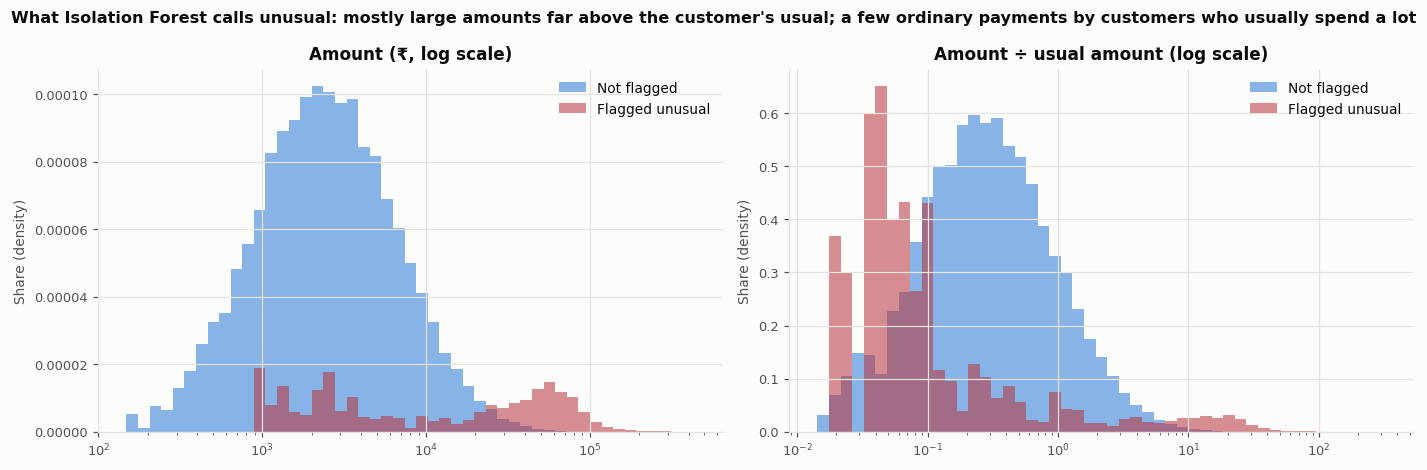

,Transactions,Fraud_rate,Median_amount,Median_usual,Share of flagged
Amount_Ratio,,,,,
Below the usual amount,62,0.0%,"₹7,848","₹36,567",9%
1–3× the usual amount,31,3.2%,"₹41,463","₹28,904",5%
Over 3× the usual amount,587,15.8%,"₹65,242","₹3,469",86%


In [6]:
profile = tx.groupby("Unusual").agg(Transactions=("Fraud_Flag", "size"), Fraud_rate=("Fraud_Flag", "mean"),
                                     Median_amount=("Amount", "median"), Median_ratio=("Amount_Ratio", "median"),
                                     Median_usual=("Historical_Avg_Transaction", "median"),
                                     Median_account_age=("Account_Age_Months", "median"),
                                     Median_frequency=("Transaction_Frequency", "median"))
profile.index = ["Not flagged", "Flagged unusual"]
display(profile.style.format({"Transactions": "{:,.0f}", "Fraud_rate": "{:.2%}", "Median_amount": "₹{:,.0f}",
                              "Median_ratio": "{:.2f}", "Median_usual": "₹{:,.0f}", "Median_account_age": "{:.0f}",
                              "Median_frequency": "{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, col, title in [(axes[0], "Amount", "Amount (₹, log scale)"), (axes[1], "Amount_Ratio", "Amount ÷ usual amount (log scale)")]:
    for flag, colour, label in [(False, NORMAL, "Not flagged"), (True, FRAUD, "Flagged unusual")]:
        v = tx.loc[tx.Unusual == flag, col]
        ax.hist(v, bins=np.logspace(np.log10(tx[col].min()), np.log10(tx[col].max()), 50), density=True, alpha=0.55,
                color=colour, label=label)
    ax.set_xscale("log"); ax.set_title(title); ax.set_ylabel("Share (density)"); ax.legend(frameon=False)
fig.suptitle("What Isolation Forest calls unusual: mostly large amounts far above the customer's usual; "
             "a few ordinary payments by customers who usually spend a lot", fontsize=10.5, fontweight="bold")
fig.tight_layout(); save_chart(fig, "01_what_is_unusual"); plt.show()

# Unusual in which direction? Split the flagged transactions by the amount against the customer's usual amount.
flag_kind = pd.cut(tx.loc[tx.Unusual, "Amount_Ratio"], [0, 1, 3, np.inf],
                   labels=["Below the usual amount", "1–3× the usual amount", "Over 3× the usual amount"])
kinds = tx[tx.Unusual].groupby(flag_kind, observed=True).agg(
    Transactions=("Fraud_Flag", "size"), Fraud_rate=("Fraud_Flag", "mean"), Median_amount=("Amount", "median"),
    Median_usual=("Historical_Avg_Transaction", "median"))
kinds["Share of flagged"] = kinds.Transactions / kinds.Transactions.sum()
kinds.style.format({"Fraud_rate": "{:.1%}", "Median_amount": "₹{:,.0f}", "Median_usual": "₹{:,.0f}",
                    "Share of flagged": "{:.0%}"})

## 6. The comparison on 6,000 test transactions (decision M3-15)

All three rankings are judged on the **same 6,000 test transactions** (May–Aug 2026), which none of them learned from:

| Ranking | Learns from the fraud label? |
| --- | --- |
| Amount alone (benchmark): largest first | No model at all |
| Supervised (Task 2): P(fraud) | Yes |
| **Isolation Forest (a): anomaly score** | **No** |
| Isolation Forest (b), side check | No (inputs chosen with Task 1's findings) |

**Bootstrap 95% ranges:** the 6,000 transactions are resampled 1,000 times and every measure recomputed. The difference between two methods is computed on the same resample each time, so the range of a difference is fair.

In [7]:
RANKINGS = {"Amount alone": test.Amount.to_numpy(float), "Supervised (Task 2)": test.P_fraud.to_numpy(),
            "Isolation Forest (a)": test.Anomaly_Score.to_numpy(), "Isolation Forest (b), side check": test.Anomaly_Score_Side.to_numpy()}


def catch(scores, y, amount, share):
    """Investigate the top `share` by score: share of frauds and of fraud ₹ caught, and precision."""
    k = max(1, int(round(share * len(scores))))
    top = np.argsort(-scores, kind="stable")[:k]
    return y[top].sum() / y.sum(), (amount[top] * y[top]).sum() / (amount * y).sum(), y[top].mean()


def measures(s, y, amt):
    out = {"PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s)}
    for share in BUDGETS:
        r, m, _ = catch(s, y, amt, share)
        out[f"Frauds caught, top {share:.0%}"], out[f"Fraud ₹ caught, top {share:.0%}"] = r, m
    return out


point = pd.DataFrame({name: measures(s, y_test, amt_test) for name, s in RANKINGS.items()})
rng = np.random.default_rng(SEED)
boot = {name: [] for name in RANKINGS}
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    for name, s in RANKINGS.items():
        boot[name].append(measures(s[i], y_test[i], amt_test[i]))
boot = {name: pd.DataFrame(v) for name, v in boot.items()}

comparison = []
for m in point.index:
    row = {"Measure": m}
    for name in RANKINGS:
        row[name] = point.loc[m, name]
    for a, b in [("Isolation Forest (a)", "Supervised (Task 2)"), ("Isolation Forest (a)", "Amount alone")]:
        d = boot[a][m] - boot[b][m]
        row[f"{a} − {b}"] = point.loc[m, a] - point.loc[m, b]
        row[f"{a} − {b}: 95% range"] = f"{d.quantile(0.025):+.3f} to {d.quantile(0.975):+.3f}"
    comparison.append(row)
comparison = pd.DataFrame(comparison)
save_table(comparison.round(4), "comparison")
print(f"Test transactions: {len(y_test):,}; frauds: {y_test.sum()}; guessing PR-AUC = {y_test.mean():.3f}")
comparison.style.format({c: "{:.3f}" for c in comparison.columns if c not in ("Measure",) and "range" not in c}).hide(axis="index")

Test transactions: 6,000; frauds: 144; guessing PR-AUC = 0.024


Measure,Amount alone,Supervised (Task 2),Isolation Forest (a),"Isolation Forest (b), side check",Isolation Forest (a) − Supervised (Task 2),Isolation Forest (a) − Supervised (Task 2): 95% range,Isolation Forest (a) − Amount alone,Isolation Forest (a) − Amount alone: 95% range
PR-AUC,0.103,0.124,0.074,0.094,-0.050,-0.079 to -0.022,-0.028,-0.043 to -0.009
ROC-AUC,0.787,0.815,0.721,0.773,-0.095,-0.131 to -0.055,-0.066,-0.103 to -0.028
"Frauds caught, top 1%",0.062,0.083,0.062,0.062,-0.021,-0.065 to +0.033,0.000,-0.030 to +0.038
"Fraud ₹ caught, top 1%",0.197,0.133,0.177,0.170,0.044,-0.061 to +0.151,-0.020,-0.109 to +0.059
"Frauds caught, top 5%",0.285,0.333,0.215,0.243,-0.118,-0.189 to -0.049,-0.069,-0.137 to -0.006
"Fraud ₹ caught, top 5%",0.561,0.552,0.446,0.493,-0.106,-0.235 to +0.012,-0.115,-0.210 to -0.035
"Frauds caught, top 10%",0.562,0.549,0.333,0.472,-0.215,-0.291 to -0.139,-0.229,-0.304 to -0.150
"Fraud ₹ caught, top 10%",0.851,0.820,0.598,0.751,-0.223,-0.314 to -0.134,-0.253,-0.339 to -0.174


## 7. The finance case: frauds and ₹ caught at each investigation budget

**Investigation budget** = the share of transactions investigated, highest score first. Measured in **actual ₹** (the ₹10,000 / ₹500 costs are Task 4's). The figures are also given per 1,000 transactions, so they scale to the bank's real volume.

Fraud ₹ per 1,000 test transactions: ₹665,705


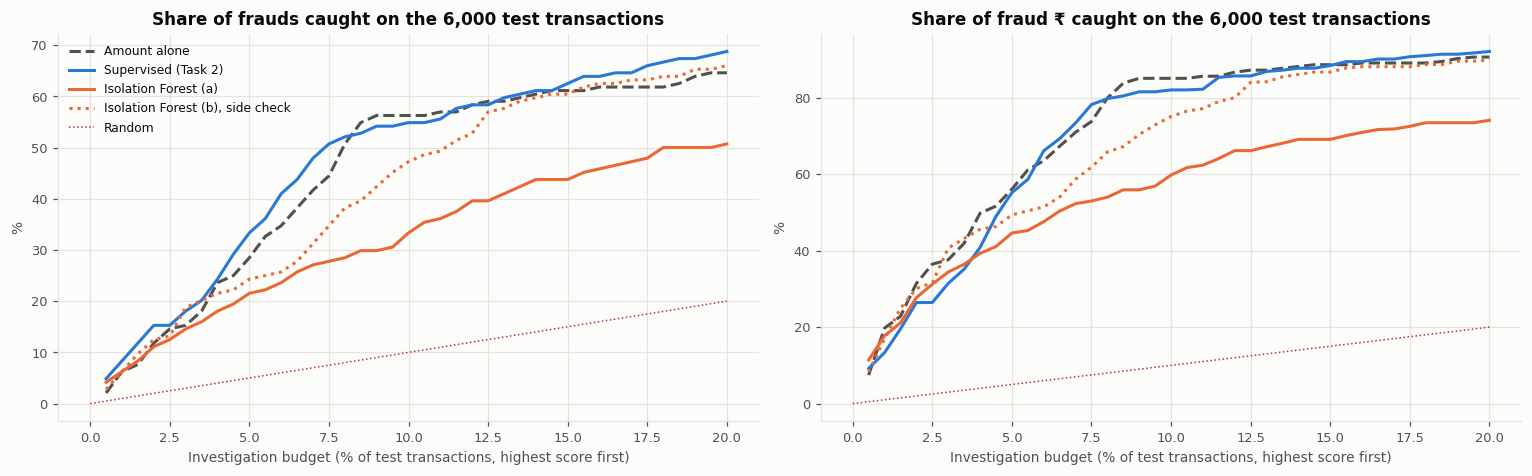

Budget,Ranking,"Investigations per 1,000",Frauds caught,Fraud ₹ caught,"Fraud ₹ caught per 1,000 transactions",₹ per investigation
1%,Amount alone,10,6.2%,19.7%,"₹131,434","₹13,143"
1%,Supervised (Task 2),10,8.3%,13.3%,"₹88,733","₹8,873"
1%,Isolation Forest (a),10,6.2%,17.7%,"₹117,975","₹11,798"
1%,"Isolation Forest (b), side check",10,6.2%,17.0%,"₹113,070","₹11,307"
5%,Amount alone,50,28.5%,56.1%,"₹373,417","₹7,468"
5%,Supervised (Task 2),50,33.3%,55.2%,"₹367,274","₹7,345"
5%,Isolation Forest (a),50,21.5%,44.6%,"₹296,929","₹5,939"
5%,"Isolation Forest (b), side check",50,24.3%,49.3%,"₹328,475","₹6,569"
10%,Amount alone,100,56.2%,85.1%,"₹566,306","₹5,663"
10%,Supervised (Task 2),100,54.9%,82.0%,"₹546,138","₹5,461"


In [8]:
shares = np.round(np.arange(0.005, 0.2001, 0.005), 3)
curves = pd.DataFrame([{"Ranking": name, "Budget": sh, **dict(zip(["Frauds caught", "Fraud ₹ caught", "Precision"],
                                                                    catch(s, y_test, amt_test, sh)))}
                       for name, s in RANKINGS.items() for sh in shares])
fraud_rupees_per_1000 = (amt_test * y_test).sum() / len(y_test) * 1000
per1000 = []
for sh in BUDGETS:
    for name in RANKINGS:
        r = curves[(curves.Ranking == name) & np.isclose(curves.Budget, sh)].iloc[0]
        per1000.append({"Budget": f"{sh:.0%}", "Ranking": name, "Investigations per 1,000": sh * 1000,
                        "Frauds caught": r["Frauds caught"], "Fraud ₹ caught": r["Fraud ₹ caught"],
                        "Fraud ₹ caught per 1,000 transactions": r["Fraud ₹ caught"] * fraud_rupees_per_1000,
                        "₹ per investigation": r["Fraud ₹ caught"] * fraud_rupees_per_1000 / (sh * 1000)})
per1000 = pd.DataFrame(per1000)
print(f"Fraud ₹ per 1,000 test transactions: ₹{fraud_rupees_per_1000:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
style = {"Amount alone": (INK_2, "--"), "Supervised (Task 2)": (BLUE, "-"), "Isolation Forest (a)": (ORANGE, "-"),
         "Isolation Forest (b), side check": (ORANGE, ":")}
for ax, col in [(axes[0], "Frauds caught"), (axes[1], "Fraud ₹ caught")]:
    for name, g in curves.groupby("Ranking", sort=False):
        ax.plot(g.Budget * 100, g[col] * 100, color=style[name][0], ls=style[name][1], lw=2, label=name)
    ax.plot([0, 20], [0, 20], color=FRAUD, ls=":", lw=1, label="Random")
    ax.set_xlabel("Investigation budget (% of test transactions, highest score first)"); ax.set_ylabel("%")
    ax.set_title(f"Share of {col.split()[0].lower()} {'₹ ' if '₹' in col else ''}caught on the 6,000 test transactions")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save_chart(fig, "02_catch_curves"); plt.show()
per1000.style.format({"Investigations per 1,000": "{:.0f}", "Frauds caught": "{:.1%}", "Fraud ₹ caught": "{:.1%}",
                      "Fraud ₹ caught per 1,000 transactions": "₹{:,.0f}", "₹ per investigation": "₹{:,.0f}"}).hide(axis="index")

## 8. Overlap: do the two methods find the same frauds?

At the same budget, compare the supervised model's top transactions with Isolation Forest's:
- how many transactions both flag;
- frauds caught by both, only by the supervised model, only by Isolation Forest, or by neither;
- **ordinary-looking frauds** (Task 1: frauds at ordinary amounts, below the training period's 80th percentile of amount): does Isolation Forest find any the supervised model misses?

In [9]:
ORDINARY_LINE = np.quantile(amt_train, 0.80)               # from training transactions only
ordinary = (test.Amount < ORDINARY_LINE).to_numpy()
overlap_rows = []
for sh in BUDGETS:
    k = int(round(sh * len(test)))
    top_sup = set(np.argsort(-test.P_fraud.to_numpy(), kind="stable")[:k])
    top_iso = set(np.argsort(-test.Anomaly_Score.to_numpy(), kind="stable")[:k])
    frauds = set(np.where(y_test == 1)[0])
    ordinary_frauds = frauds & set(np.where(ordinary)[0])
    overlap_rows.append({"Budget": f"{sh:.0%}", "Investigations each": k, "Flagged by both": len(top_sup & top_iso),
                         "Share flagged by both": len(top_sup & top_iso) / k,
                         "Frauds: both": len(frauds & top_sup & top_iso), "Frauds: supervised only": len((frauds & top_sup) - top_iso),
                         "Frauds: Isolation Forest only": len((frauds & top_iso) - top_sup),
                         "Frauds: neither": len(frauds - top_sup - top_iso),
                         "Ordinary-looking frauds caught: supervised": len(ordinary_frauds & top_sup),
                         "Ordinary-looking frauds caught: Isolation Forest": len(ordinary_frauds & top_iso),
                         "Ordinary-looking frauds in test": len(ordinary_frauds)})
overlap = pd.DataFrame(overlap_rows)
print(f"Ordinary-looking = amount below ₹{ORDINARY_LINE:,.0f} (training 80th percentile); "
      f"{(ordinary & (y_test == 1)).sum()} of {y_test.sum()} test frauds")
overlap.style.format({"Share flagged by both": "{:.0%}"}).hide(axis="index")

Ordinary-looking = amount below ₹15,162 (training 80th percentile); 51 of 144 test frauds


Budget,Investigations each,Flagged by both,Share flagged by both,Frauds: both,Frauds: supervised only,Frauds: Isolation Forest only,Frauds: neither,Ordinary-looking frauds caught: supervised,Ordinary-looking frauds caught: Isolation Forest,Ordinary-looking frauds in test
1%,60,18,30%,3,9,6,126,0,0,51
5%,300,148,49%,25,23,6,90,0,0,51
10%,600,334,56%,45,34,3,62,0,1,51


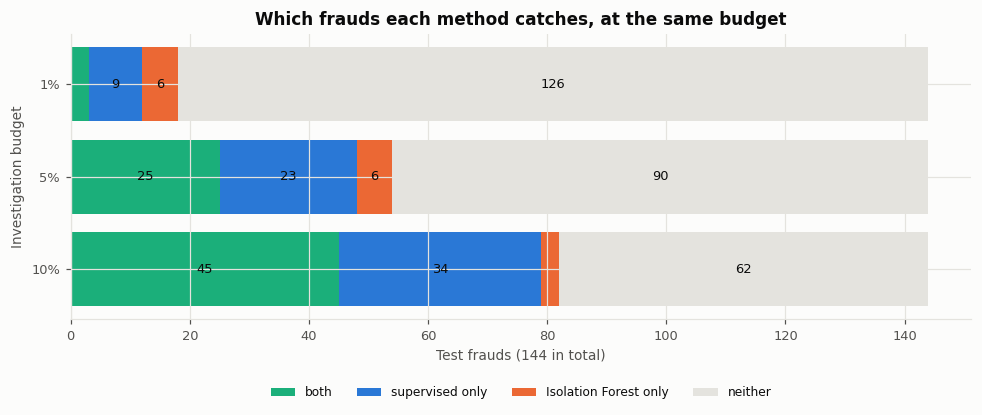

In [10]:
# Chart: frauds caught by both / only one / neither, at each budget.
fig, ax = plt.subplots(figsize=(9, 4))
parts = [("Frauds: both", AQUA), ("Frauds: supervised only", BLUE), ("Frauds: Isolation Forest only", ORANGE),
         ("Frauds: neither", GRID)]
left = np.zeros(len(overlap))
for col, colour in parts:
    ax.barh(overlap.Budget, overlap[col], left=left, color=colour, label=col.replace("Frauds: ", ""))
    for i, (l, v) in enumerate(zip(left, overlap[col])):
        if v >= 5:
            ax.text(l + v / 2, i, str(v), ha="center", va="center", fontsize=8.5)
    left += overlap[col].to_numpy()
ax.set_xlabel(f"Test frauds ({y_test.sum()} in total)"); ax.set_ylabel("Investigation budget"); ax.invert_yaxis()
ax.legend(frameon=False, ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.32))
ax.set_title("Which frauds each method catches, at the same budget")
fig.tight_layout(); save_chart(fig, "03_overlap"); plt.show()

## 9. Combining the two

Two ways to use both, at the **same number of investigations** as either method alone:
- **"Flagged by either":** take the top half of the budget from each method (the transactions both pick count once, and the freed places go to the next in line from the supervised model).
- **Blended rank:** each transaction's average position in the two rankings (as percentiles, so the two scales are comparable).

Shown for information: whether Task 4 thresholds a combination is decided there.

In [11]:
def either(sh, s1, s2):
    """Top half of the budget from each ranking, filled up to the full budget from s1."""
    k = int(round(sh * len(s1)))
    picked = list(dict.fromkeys(list(np.argsort(-s1, kind="stable")[: k // 2]) + list(np.argsort(-s2, kind="stable")[: k // 2])))
    for i in np.argsort(-s1, kind="stable"):
        if len(picked) >= k:
            break
        if i not in picked:
            picked.append(i)
    p = np.array(picked[:k])
    return y_test[p].sum() / y_test.sum(), (amt_test[p] * y_test[p]).sum() / (amt_test * y_test).sum()


blend = (pd.Series(test.P_fraud).rank(pct=True) + pd.Series(test.Anomaly_Score).rank(pct=True)).to_numpy() / 2
combo_rows = []
for sh in BUDGETS:
    for name, f in [("Supervised alone", lambda: catch(test.P_fraud.to_numpy(), y_test, amt_test, sh)[:2]),
                    ("Isolation Forest alone", lambda: catch(test.Anomaly_Score.to_numpy(), y_test, amt_test, sh)[:2]),
                    ("Flagged by either (half each)", lambda: either(sh, test.P_fraud.to_numpy(), test.Anomaly_Score.to_numpy())),
                    ("Blended rank", lambda: catch(blend, y_test, amt_test, sh)[:2])]:
        r, m = f()
        combo_rows.append({"Budget": f"{sh:.0%}", "Approach": name, "Frauds caught": r, "Fraud ₹ caught": m})
combos = pd.DataFrame(combo_rows)
print(f"Blended rank PR-AUC: {average_precision_score(y_test, blend):.3f} "
      f"(supervised {point.loc['PR-AUC', 'Supervised (Task 2)']:.3f}, Isolation Forest {point.loc['PR-AUC', 'Isolation Forest (a)']:.3f})")
combos.style.format({"Frauds caught": "{:.1%}", "Fraud ₹ caught": "{:.1%}"}).hide(axis="index")

Blended rank PR-AUC: 0.107 (supervised 0.124, Isolation Forest 0.074)


Budget,Approach,Frauds caught,Fraud ₹ caught
1%,Supervised alone,8.3%,13.3%
1%,Isolation Forest alone,6.2%,17.7%
1%,Flagged by either (half each),7.6%,17.4%
1%,Blended rank,6.2%,14.6%
5%,Supervised alone,33.3%,55.2%
5%,Isolation Forest alone,21.5%,44.6%
5%,Flagged by either (half each),25.0%,48.3%
5%,Blended rank,29.2%,55.3%
10%,Supervised alone,54.9%,82.0%
10%,Isolation Forest alone,33.3%,59.8%


## 10. The unusual transactions, each with its reason (the brief's deliverable; decision M3-17)

The brief asks to *identify transactions that appear unusual*. `unusual_transactions.csv` lists every transaction Isolation Forest flags (the top 2.25% by anomaly score, cut-off set on training), **with the reason it is unusual**.

**SHAP** (SHapley Additive exPlanations) splits each transaction's anomaly score among its inputs: how much each one made the transaction easier to isolate. The pushes add up to the score. The top reasons are then written in plain words with the actual values and how they compare with all training transactions.

```text
Score of a transaction = average score + push from Amount + push from Amount_Ratio + … + push from Hour
(SHAP for Isolation Forest explains the path length: a shorter path = more unusual, so a negative SHAP value pushes towards "unusual")
```

Alongside, for comparison: the supervised model's P(fraud), whether it would also flag the transaction (top 2.25% of its own scores, cut-off set on training), and whether the transaction was in fact fraud.

In [12]:
flagged = tx[tx.Unusual].copy()
explainer = shap.TreeExplainer(iso)
sv = explainer.shap_values(flagged[MAIN_INPUTS].to_numpy(float))
push = pd.DataFrame(-sv, columns=MAIN_INPUTS, index=flagged.index)      # positive = pushes towards unusual

ref = train[MAIN_INPUTS]                                                # describe values against training transactions


def describe(col, value, row):
    """One reason in plain words, with the value and where it sits among training transactions."""
    pct = (ref[col] < value).mean()
    where = f"top {max(1, round((1 - pct) * 100))}%" if pct >= 0.5 else f"lowest {max(1, round(pct * 100))}%"
    if col == "Amount":
        return f"amount ₹{value:,.0f} ({where} of amounts)"
    if col == "Amount_Ratio":
        return f"{value:.1f}× the customer's usual ₹{row.Historical_Avg_Transaction:,.0f} ({where} of ratios)"
    if col == "Historical_Avg_Transaction":
        return f"customer's usual amount ₹{value:,.0f} ({where})"
    if col == "Account_Age_Months":
        return f"account {value:.0f} months old ({where})"
    if col == "Transaction_Frequency":
        return f"transaction frequency {value:.0f} ({where})"
    return f"at {value:02.0f}:00 ({where} of hours)"


sup_cut = np.quantile(train.P_fraud, 1 - FRAUD_SHARE)                  # supervised model's own top 2.25%, set on training
reasons, first_reason = [], []
for idx, row in flagged.iterrows():
    top = push.loc[idx].sort_values(ascending=False)
    top = top[top > 0].head(3).index
    reasons.append("; ".join(describe(c, row[c], row) for c in top))
    first_reason.append(top[0])
flagged["Why unusual"] = reasons
flagged["Anomaly rank"] = flagged.Anomaly_Score.rank(ascending=False, method="first").astype(int)
unusual = pd.DataFrame({
    "Transaction_ID": flagged.Transaction_ID, "Date": flagged.Timestamp.dt.date.astype(str), "Set": flagged.Set,
    "Amount (₹)": flagged.Amount.round(2), "Transaction_Type": flagged.Transaction_Type.astype(str),
    "Location": flagged.Location.astype(str), "Anomaly score": flagged.Anomaly_Score.round(4),
    "Anomaly rank": flagged["Anomaly rank"], "Why unusual": flagged["Why unusual"],
    "Supervised P(fraud)": flagged.P_fraud.round(4),
    "Also flagged by supervised model": np.where(flagged.P_fraud >= sup_cut, "Yes", "No"),
    "Actually fraud": np.where(flagged.Fraud_Flag == 1, "Yes", "No")}).sort_values("Anomaly rank")
assert unusual.notna().all().all() and (unusual["Why unusual"] != "").all()
save_table(unusual, "unusual_transactions")

summ = unusual.groupby("Set").agg(Flagged=("Transaction_ID", "size"),
                                  Fraud=("Actually fraud", lambda s: (s == "Yes").mean()),
                                  Also_supervised=("Also flagged by supervised model", lambda s: (s == "Yes").mean()))
display(summ.style.format({"Fraud": "{:.1%}", "Also_supervised": "{:.0%}"}))
print("Main reason (the input pushing hardest towards 'unusual'):",
      pd.Series(first_reason).value_counts().to_dict())
unusual.head(8)

,Flagged,Fraud,Also_supervised
Set,,,
test,140,12.1%,36%
train,540,14.3%,43%


Main reason (the input pushing hardest towards 'unusual'): {'Amount_Ratio': 325, 'Amount': 265, 'Historical_Avg_Transaction': 85, 'Transaction_Frequency': 5}


,Transaction_ID,Date,Set,Amount (₹),Transaction_Type,Location,Anomaly score,Anomaly rank,Why unusual,Supervised P(fraud),Also flagged by supervised model,Actually fraud
1614,5001615,2025-02-02,train,266293.08,Transfer,Mumbai,0.7318,1,"81.1× the customer's usual ₹3,282 (top 1% of ratios); amount ₹266,293 (top 1% of amounts); transaction frequency 3 (...",0.2113,Yes,Yes
8102,5008103,2025-06-13,train,280895.37,Payment,Hyderabad,0.7291,2,"86.4× the customer's usual ₹3,251 (top 1% of ratios); amount ₹280,895 (top 1% of amounts); account 6 months old (low...",0.1735,Yes,No
27282,5027283,2026-07-07,test,232064.97,Transfer,Hyderabad,0.7284,3,"73.6× the customer's usual ₹3,153 (top 1% of ratios); amount ₹232,065 (top 1% of amounts); at 00:00 (lowest 1% of ho...",0.2272,Yes,No
12358,5012359,2025-09-08,train,160859.35,Transfer,Mumbai,0.7239,4,"183.0× the customer's usual ₹879 (top 1% of ratios); amount ₹160,859 (top 1% of amounts); at 01:00 (lowest 4% of hours)",0.3440,Yes,Yes
14266,5014267,2025-10-16,train,92817.33,Withdrawal,Delhi,0.7238,5,"96.3× the customer's usual ₹964 (top 1% of ratios); amount ₹92,817 (top 1% of amounts); transaction frequency 16 (to...",0.2786,Yes,No
4402,5004403,2025-03-31,train,179377.39,Withdrawal,Chennai,0.7233,6,"61.6× the customer's usual ₹2,913 (top 1% of ratios); amount ₹179,377 (top 1% of amounts); at 01:00 (lowest 4% of ho...",0.1817,Yes,No
20483,5020484,2026-02-19,train,200361.02,Payment,Delhi,0.7217,7,"58.6× the customer's usual ₹3,419 (top 1% of ratios); amount ₹200,361 (top 1% of amounts); account 7 months old (low...",0.1740,Yes,No
3692,5003693,2025-03-16,train,261476.00,Payment,Mumbai,0.7203,8,"69.0× the customer's usual ₹3,788 (top 1% of ratios); amount ₹261,476 (top 1% of amounts); account 6 months old (low...",0.1681,Yes,Yes


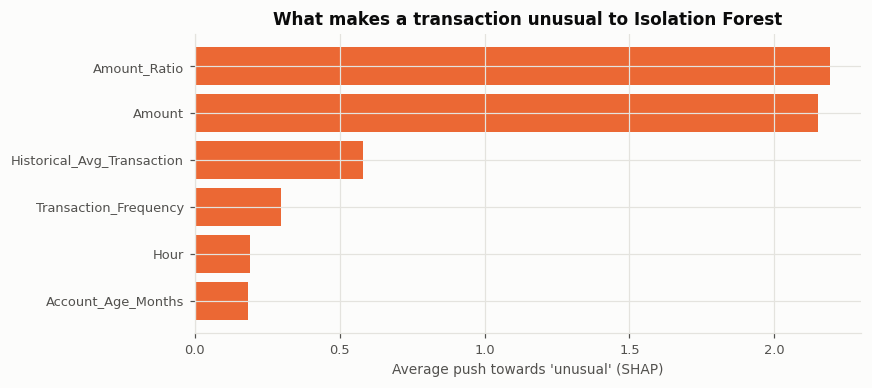

In [13]:
# Chart: what makes transactions unusual, over all flagged transactions (mean push per input).
imp = push.clip(lower=0).mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(imp.index, imp.values, color=ORANGE)
ax.set_xlabel("Average push towards 'unusual' (SHAP)"); ax.set_title("What makes a transaction unusual to Isolation Forest")
fig.tight_layout(); save_chart(fig, "04_why_unusual"); plt.show()

## 11. What the results say

### What Isolation Forest calls unusual (steps 4–5)
- Fitted on the 24,000 training transactions **without the fraud label**. It flags the 2.25% with the highest anomaly scores: 540 training and 140 test transactions, 680 in all. Two random seeds share 93% of the list.
- **The flagged transactions are about six times riskier than the rest:** 13.8% fraud against 2.0%. Their median amount is ₹60,518 against ₹6,374.
- **But "unusual" isn't the same as "fraud":**

| Flagged transactions | Share of the list | Fraud rate |
| --- | --- | --- |
| Over 3× the customer's usual amount | 86% (587) | **15.8%** |
| 1–3× the usual amount | 5% (31) | 3.2% |
| **Below the usual amount** (ordinary payments by customers who usually spend about ₹36,600) | 9% (62) | **0%** |

- **Why these 62 get flagged:** a customer whose usual amount is very high is itself rare, so Isolation Forest isolates them whatever they pay. None of the 62 was fraud.

### The input tests (step 3)
- **Six numeric descriptors on raw ₹ (chosen without fraud information):** PR-AUC 0.087–0.092 on training transactions.
  - With money logged it falls to 0.043–0.054. Isolation Forest then also flags tiny transactions: 55% of its top 5% fall below the median amount.
  - With all 28 Task 2 inputs it is 0.029–0.030, close to guessing (0.022).
- **Category columns don't help in any form tested:** value frequency, combination rarity, device or city change, a city or type new to the customer. Alone they score 0.023, the same as guessing.
  - Every city, merchant and weekday holds 14–15% of transactions, so no value is rare.
  - Fraud is no higher where categories look unusual: 2.7% vs 2.2% for the rarest combinations; 2.2% vs 2.3% for a new city.

### The comparison on 6,000 test transactions (step 6)

| Measure | Amount alone | Supervised (Task 2) | **Isolation Forest (a)** | Isolation Forest (b), side check |
| --- | --- | --- | --- | --- |
| PR-AUC (guessing 0.024) | 0.103 | **0.124** | **0.075** | 0.094 |
| ROC-AUC | 0.787 | **0.815** | **0.721** | 0.773 |
| Frauds caught, top 5% | 28.5% | **33.3%** | 21.5% | 24.3% |
| Fraud ₹ caught, top 5% | 56.1% | 55.2% | 44.6% | 49.3% |
| Frauds caught, top 10% | **56.2%** | 54.9% | 33.3% | 47.2% |
| Fraud ₹ caught, top 10% | **85.1%** | 82.0% | 59.8% | 75.1% |

**Isolation Forest (a) against the others (bootstrap 95% ranges):**

| Against | PR-AUC | ROC-AUC | Fraud ₹ caught, top 10% |
| --- | --- | --- | --- |
| Supervised | **−0.050 (−0.079 to −0.022)** | **−0.095 (−0.131 to −0.055)** | **−22 points (−31 to −13)** |
| Amount alone | **−0.029 (−0.043 to −0.009)** | **−0.066 (−0.103 to −0.028)** | **−25 points (−34 to −17)** |

- **Isolation Forest finds far more fraud than chance, but less than either the supervised model or the simple amount rule,** and the PR-AUC, ROC-AUC and top-10% gaps are beyond chance (at 1% and 5% some are within chance).
- **Only at the very top (1%) does it match them on ₹** (17.7% of fraud ₹, against 19.7% for amount and 13.3% for supervised). Its most extreme flags are the huge, very unusual transactions.
- **The side check (b) narrows the gap but doesn't close it:** PR-AUC 0.094, still below amount alone. So the gap is mostly built into the method: being unusual doesn't make a transaction fraud. The choice of inputs is only part of it.

### Overlap: do the two methods find the same frauds? (step 8)

| Investigation budget | Same transactions in both lists | Frauds caught by both | Supervised only | **Isolation Forest only** | Neither |
| --- | --- | --- | --- | --- | --- |
| 1% (60 each) | 30% | 3 | 9 | **6** | 126 |
| 5% (300 each) | 49% | 25 | 23 | **6** | 90 |
| 10% (600 each) | 56% | 45 | 34 | **3** | 62 |

- **Isolation Forest adds very few frauds the supervised model misses:** 3–6 of 144.
- **Neither method finds the ordinary-looking frauds.** Of the 51 test frauds below ₹15,162 (the training 80th percentile of amount), the supervised model catches none in its top 10%, and Isolation Forest catches 1. Nothing in this data marks them out, labelled or not.

### Combining the two (step 9)

| Same number of investigations | Top 5%: frauds / fraud ₹ | Top 10%: frauds / fraud ₹ |
| --- | --- | --- |
| Supervised alone | 33.3% / 55.2% | 54.9% / 82.0% |
| Flagged by either (half each) | 25.0% / 48.3% | 53.5% / 82.5% |
| Blended rank | 29.2% / 55.3% | 48.6% / 76.8% |

- **Combining doesn't help:** each investigation given to Isolation Forest's picks is taken from better supervised picks. The blended rank's PR-AUC (0.107) is below the supervised model alone (0.124).

### The finance case (step 7)
₹6.66 lakh of fraud passes through every 1,000 test transactions.

| Investigate per 1,000 transactions | Amount alone | Supervised | Isolation Forest (a) |
| --- | --- | --- | --- |
| 50 (5%) | ₹3.73 lakh caught (₹7,468 per investigation) | ₹3.67 lakh (₹7,345) | ₹2.97 lakh (₹5,939) |
| 100 (10%) | ₹5.66 lakh (₹5,663) | ₹5.46 lakh (₹5,461) | ₹3.98 lakh (₹3,980) |

At the same workload, Isolation Forest finds about ₹1.7 lakh less fraud per 1,000 transactions at a 10% budget.

### The unusual transactions, with reasons (step 10)
- **`unusual_transactions.csv`** lists all 680, each with its reasons in words (SHAP). For example: *"81.1× the customer's usual ₹3,282 (top 1% of ratios); amount ₹2,66,293 (top 1% of amounts)"*.
- **What makes a transaction unusual (SHAP):** the main reason is the amount ratio for 325 of the 680 flags, the amount for 265, and the customer's (very high) usual amount for 85: the big spenders. Frequency is the main reason for 5; hour and account age never.
- **Agreement with the supervised model:** it would also flag 43% of the training list and 36% of the test list in its own top 2.25%. The two methods agree on the extreme cases and part ways after that.

### What this means, and what goes to Task 4
- **Answer to the brief's comparison:** supervised detection is better here than anomaly detection, beyond chance. Anomaly detection flags transactions about six times riskier than average, without ever seeing a fraud label, but "unusual" includes harmless oddities such as big spenders' ordinary payments.
- **Where anomaly detection would earn its place:** as a check for *new* kinds of fraud the labels haven't caught yet, or where no labels exist. In this data it adds only 3–6 frauds the supervised model misses.
- **To Task 4:** `FINAL_M3_T3_anomaly_scores.csv` (each transaction's anomaly score, beside Task 2's P(fraud)). The evidence favours setting the threshold on the supervised score, or on P(fraud) × amount. The anomaly score is not a probability, so any threshold on it can only be found by sweeping costs.

## 12. Save the outputs (decision M3-16)

- **`unusual_transactions.csv`: the brief's deliverable** (saved in step 10).
- **`FINAL_M3_T3_anomaly_scores.csv`: the hand-off to Task 4.** Every transaction's anomaly score, beside Task 2's file.
- **`comparison.csv`:** amount alone vs supervised vs Isolation Forest on the test transactions (saved in step 6).
- `isolation_forest.joblib` / `.json`: the fitted model and its settings.
- The charts above and `key_numbers.json`. Every other table is shown above and in the report.

In [14]:
scores = tx[["Transaction_ID", "Set", "Fraud_Flag", "Amount", "Anomaly_Score", "Anomaly_Score_Side", "Unusual"]].copy()
scores["Set"] = scores.Set.map({"train": "train (fitted on, no label)", "test": "test"})
scores["Unusual"] = np.where(scores.Unusual, "Yes", "No")
assert scores.Transaction_ID.is_unique and len(scores) == 30000
save_table(scores.round(6), "FINAL_M3_T3_anomaly_scores")
joblib.dump(iso, OUT_DIR / "isolation_forest.joblib")
(OUT_DIR / "isolation_forest.json").write_text(json.dumps({
    "inputs": MAIN_INPUTS, "n_estimators": N_TREES, "max_samples": SAMPLE, "share_flagged": round(FRAUD_SHARE, 4),
    "cutoff_score": round(float(CUTOFF), 6), "fitted_on": "24,000 training transactions, no fraud label", "seed": SEED},
    indent=1), encoding="utf-8")


def r4(v):
    return round(float(v), 4)


key = {
    "share_flagged": r4(FRAUD_SHARE), "cutoff": r4(CUTOFF), "stability": [r4(v) for v in STABILITY],
    "flagged": {s: int(v) for s, v in tx.groupby("Set").Unusual.sum().items()},
    "flagged_fraud_rate": {s: r4(v) for s, v in tx[tx.Unusual].groupby("Set").Fraud_Flag.mean().items()},
    "test": {name: {m: r4(point.loc[m, name]) for m in point.index} for name in RANKINGS},
    "overlap": overlap.set_index("Budget")[["Share flagged by both", "Frauds: both", "Frauds: supervised only",
                                            "Frauds: Isolation Forest only", "Frauds: neither"]].astype(float).round(4).to_dict(orient="index"),
    "blend_pr_auc": r4(average_precision_score(y_test, blend)),
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_03_fraud_detection/outputs/task3
['01_what_is_unusual.png', '02_catch_curves.png', '03_overlap.png', '04_why_unusual.png', 'FINAL_M3_T3_anomaly_scores.csv', 'comparison.csv', 'isolation_forest.joblib', 'isolation_forest.json', 'key_numbers.json', 'unusual_transactions.csv']
